### Part A: Conceptual Foundation (Theory)

*   **Ensemble Learning Methods:** These methods combine multiple machine learning models (often weak learners) to create a single, more powerful predictive model. They are effective because they reduce the risk of overfitting, improve generalization, and increase overall accuracy compared to single models.

*   **Bagging, Boosting, and Voting:** **Bagging** (Bootstrap Aggregating) trains multiple independent models in parallel on random subsets of data and averages their predictions to reduce variance. **Boosting** trains models sequentially, where each new model corrects the errors of the previous ones to reduce bias. **Voting** combines the predictions of multiple diverse base models (e.g., Logistic Regression, SVM, Random Forest) trained on the same dataset, choosing the final output by majority vote (classification) or average (regression).

*   **Bias–Variance Trade-off:** Bias is the error from erroneous assumptions in the learning algorithm, while variance is the error from sensitivity to small fluctuations in the training set. Ensemble methods address this: bagging primarily reduces high variance (overfitting), and boosting primarily reduces high bias (underfitting), finding an optimal balance.

*   **Voting Classifier and Stacking Ensemble:** A **Voting Classifier** aggregates the predictions of several independent base estimators using a majority rule (hard voting) or averaged probabilities (soft voting). A **Stacking Ensemble** goes a step further by training a new "meta-learner" model on the predictions (outputs) of the base estimators to make the final prediction.

*   **AdaBoost vs. XGBoost:** **AdaBoost** adjusts the weights of incorrectly classified instances so subsequent weak learners focus more on difficult cases. **XGBoost** (Extreme Gradient Boosting) is a highly optimized gradient boosting framework that minimizes a regularized objective function using gradient descent, offering better handling of missing values, parallel processing, and built-in cross-validation, making it generally faster and more powerful than AdaBoost.

In [25]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             roc_auc_score, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor, AdaBoostClassifier, 
                              AdaBoostRegressor, VotingClassifier, VotingRegressor, 
                              StackingClassifier, StackingRegressor)
from xgboost import XGBClassifier, XGBRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from pathlib import Path
import joblib

In [2]:
base_path = Path().cwd().parent
model_path = base_path/"Model"
data_path = base_path/"Data"/"Smart_Outcome_Predictor_Dataset_5200.xlsx"

# 🧪 Part B: Dataset Understanding & Preparation

In [3]:
DF = pd.read_excel(data_path)
DF

,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5195,705196,28,Asia,Tablet,WorkingPro,Advanced,Data,2024-08-26,35,27,26.1,28,7,8,1,77.2,0.897,1,97.4
5196,705197,28,Africa,Tablet,Graduate,Beginner,Design,2024-04-27,17,21,3.9,31,8,4,0,82.4,0.743,1,71.9
5197,705198,22,Asia,Laptop,Undergrad,Intermediate,Marketing,2024-08-01,31,32,12.8,43,7,2,0,62.4,0.757,1,71.5
5198,705199,25,Asia,Laptop,Graduate,Beginner,Programming,2024-01-18,3,16,27.1,21,5,8,2,76.1,0.847,0,86.8


In [4]:
DF.head()

,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [5]:
DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   student_id             5200 non-null   int64         
 1   age                    5200 non-null   int64         
 2   country_region         5200 non-null   object        
 3   device_type            5200 non-null   object        
 4   education_background   5200 non-null   object        
 5   course_level           5200 non-null   object        
 6   course_category        5200 non-null   object        
 7   course_start_date      5200 non-null   datetime64[ns]
 8   week_of_year           5200 non-null   int64         
 9   sessions               5200 non-null   int64         
 10  time_spent_hours       5088 non-null   float64       
 11  videos_watched         5200 non-null   int64         
 12  quiz_attempts          5200 non-null   int64         
 13  ass

In [6]:
DF.shape

(5200, 19)

In [7]:
DF.isnull().sum()

student_id                 0
age                        0
country_region             0
device_type                0
education_background       0
course_level               0
course_category            0
course_start_date          0
week_of_year               0
sessions                   0
time_spent_hours         112
videos_watched             0
quiz_attempts              0
assignments_submitted      0
forum_posts                0
avg_quiz_score            81
attendance_rate           80
completion_status          0
final_score                0
dtype: int64

In [8]:
DF.duplicated().sum()

np.int64(0)

In [9]:
DF.describe()

,student_id,age,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
count,5200.000000,5200.000000,5200,5200.000000,5200.000000,5088.000000,5200.000000,5200.000000,5200.000000,5200.000000,5119.000000,5120.000000,5200.000000,5200.000000
mean,702600.500000,24.339615,2024-07-02 09:45:24.923076864,26.621538,19.121923,18.216156,25.852885,6.995769,3.835769,1.585577,66.842626,0.847189,0.375385,74.821615
min,700001.000000,16.000000,2024-01-01 00:00:00,1.000000,1.000000,0.600000,0.000000,0.000000,0.000000,0.000000,0.000000,0.313000,0.000000,35.200000
25%,701300.750000,20.000000,2024-04-02 00:00:00,14.000000,11.000000,10.300000,13.000000,5.000000,2.000000,1.000000,57.500000,0.768750,0.000000,64.700000
50%,702600.500000,24.000000,2024-07-02 00:00:00,27.000000,17.000000,16.100000,23.000000,7.000000,4.000000,1.000000,66.900000,0.855000,0.000000,74.100000
75%,703900.250000,28.000000,2024-10-01 00:00:00,40.000000,25.000000,23.800000,35.000000,9.000000,5.000000,2.000000,76.200000,0.942000,1.000000,84.900000
max,705200.000000,45.000000,2024-12-30 00:00:00,52.000000,94.000000,76.800000,158.000000,20.000000,12.000000,8.000000,100.000000,1.000000,1.000000,100.000000
std,1501.255031,5.578864,NaN,15.007731,10.726708,10.734114,17.720493,2.568017,1.951802,1.270640,13.813992,0.113545,0.484269,13.531829


In [10]:
target_clf = 'completion_status'
target_reg = 'final_score'

In [12]:
X = DF.drop(columns=[target_clf, target_reg])
y_clf = DF[target_clf]
y_reg = DF[target_reg]

In [13]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

In [14]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [16]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.2, random_state=42)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)

In [17]:
def evaluate_classification(model, name, X_train, y_train, X_test, y_test):
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    try:
        y_prob = pipe.predict_proba(X_test)[:, 1]
        roc = roc_auc_score(y_test, y_prob)
    except AttributeError:
        roc = roc_auc_score(y_test, y_pred)
        
    print(f"[{name}] Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f} | ROC-AUC: {roc:.4f}")

In [18]:
def evaluate_regression(model, name, X_train, y_train, X_test, y_test):
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    print(f"[{name}] MAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}")

# 📦 Part C: Bagging (Bootstrap Aggregating)

In [19]:
base_dt_clf = DecisionTreeClassifier(random_state=42)
base_dt_reg = DecisionTreeRegressor(random_state=42)

In [20]:
bagging_clf = BaggingClassifier(estimator=base_dt_clf, n_estimators=50, random_state=42)
bagging_reg = BaggingRegressor(estimator=base_dt_reg, n_estimators=50, random_state=42)

In [21]:
evaluate_classification(base_dt_clf, "Single Base Tree (Clf)", X_train_c, y_train_c, X_test_c, y_test_c)
evaluate_classification(bagging_clf, "Bagging (Clf)", X_train_c, y_train_c, X_test_c, y_test_c)

[Single Base Tree (Clf)] Acc: 0.6385 | Prec: 0.5219 | Rec: 0.5165 | F1: 0.5192 | ROC-AUC: 0.6145
[Bagging (Clf)] Acc: 0.6981 | Prec: 0.6254 | Rec: 0.5013 | F1: 0.5565 | ROC-AUC: 0.7500


In [32]:
evaluate_regression(base_dt_reg, "Single Base Tree (Reg)", X_train_r, y_train_r, X_test_r, y_test_r)
evaluate_regression(bagging_reg, "Bagging (Reg)", X_train_r, y_train_r, X_test_r, y_test_r)

[Single Base Tree (Reg)] MAE: 11.2529 | RMSE: 14.2233 | R²: -0.0828
[Bagging (Reg)] MAE: 8.0491 | RMSE: 10.0966 | R²: 0.4544


# ⚡ Part D: Boosting Algorithms

In [27]:
adaboost_clf = AdaBoostClassifier(n_estimators=50, random_state=42)
adaboost_reg = AdaBoostRegressor(n_estimators=50, random_state=42)

In [28]:
xgboost_clf = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgboost_reg = XGBRegressor(random_state=42)

In [29]:
evaluate_classification(adaboost_clf, "AdaBoost (Clf)", X_train_c, y_train_c, X_test_c, y_test_c)
evaluate_classification(xgboost_clf, "XGBoost (Clf)", X_train_c, y_train_c, X_test_c, y_test_c)

[AdaBoost (Clf)] Acc: 0.7192 | Prec: 0.6554 | Rec: 0.5420 | F1: 0.5933 | ROC-AUC: 0.7665
[XGBoost (Clf)] Acc: 0.6942 | Prec: 0.6093 | Rec: 0.5318 | F1: 0.5679 | ROC-AUC: 0.7375


In [31]:
evaluate_regression(adaboost_reg, "AdaBoost (Reg)", X_train_r, y_train_r, X_test_r, y_test_r)
evaluate_regression(xgboost_reg, "XGBoost (Reg)", X_train_r, y_train_r, X_test_r, y_test_r)

[AdaBoost (Reg)] MAE: 8.6165 | RMSE: 10.5588 | R²: 0.4033
[XGBoost (Reg)] MAE: 8.4969 | RMSE: 10.6451 | R²: 0.3935


# 🗳️ Part E: Voting & Stacking Ensembles

In [33]:
voting_hard_clf = VotingClassifier(estimators=[
    ('rf', bagging_clf), ('xgb', xgboost_clf)
], voting='hard')

voting_soft_clf = VotingClassifier(estimators=[
    ('rf', bagging_clf), ('xgb', xgboost_clf)
], voting='soft')

In [34]:
voting_reg = VotingRegressor(estimators=[
    ('rf', bagging_reg), ('xgb', xgboost_reg)
])

In [36]:
stacking_clf = StackingClassifier(
    estimators=[('rf', bagging_clf), ('xgb', xgboost_clf)], 
    final_estimator=LogisticRegression()
)

stacking_reg = StackingRegressor(
    estimators=[('rf', bagging_reg), ('xgb', xgboost_reg)], 
    final_estimator=LinearRegression())

In [37]:
evaluate_classification(voting_hard_clf, "Hard Voting (Clf)", X_train_c, y_train_c, X_test_c, y_test_c)
evaluate_classification(voting_soft_clf, "Soft Voting (Clf)", X_train_c, y_train_c, X_test_c, y_test_c)
evaluate_classification(stacking_clf, "Stacking (Clf)", X_train_c, y_train_c, X_test_c, y_test_c)

[Hard Voting (Clf)] Acc: 0.7077 | Prec: 0.6787 | Rec: 0.4300 | F1: 0.5265 | ROC-AUC: 0.6532
[Soft Voting (Clf)] Acc: 0.7048 | Prec: 0.6311 | Rec: 0.5267 | F1: 0.5742 | ROC-AUC: 0.7511
[Stacking (Clf)] Acc: 0.7077 | Prec: 0.6561 | Rec: 0.4758 | F1: 0.5516 | ROC-AUC: 0.7526


In [38]:
evaluate_regression(voting_reg, "Voting (Reg)", X_train_r, y_train_r, X_test_r, y_test_r)
evaluate_regression(stacking_reg, "Stacking (Reg)", X_train_r, y_train_r, X_test_r, y_test_r)

[Voting (Reg)] MAE: 8.0855 | RMSE: 10.1381 | R²: 0.4499
[Stacking (Reg)] MAE: 8.0322 | RMSE: 10.0582 | R²: 0.4585


# 📊 Part F: Model Evaluation & Comparison

In [44]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingClassifier, AdaBoostClassifier,
    VotingClassifier, StackingClassifier,
    BaggingRegressor, AdaBoostRegressor,
    VotingRegressor, StackingRegressor
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from xgboost import XGBClassifier, XGBRegressor

# Base models
base_clf = DecisionTreeClassifier(random_state=42)
base_reg = DecisionTreeRegressor(random_state=42)

# Classification models
classification_models = {
    "Base Decision Tree": base_clf,

    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=50,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=50,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=42
    ),

    "Voting (Hard)": VotingClassifier(
        estimators=[
            ("dt", DecisionTreeClassifier(random_state=42)),
            ("xgb", XGBClassifier(eval_metric="logloss", random_state=42))
        ],
        voting="hard"
    ),

    "Voting (Soft)": VotingClassifier(
        estimators=[
            ("dt", DecisionTreeClassifier(random_state=42)),
            ("xgb", XGBClassifier(eval_metric="logloss", random_state=42))
        ],
        voting="soft"
    ),

    "Stacking": StackingClassifier(
        estimators=[
            ("dt", DecisionTreeClassifier(random_state=42)),
            ("xgb", XGBClassifier(eval_metric="logloss", random_state=42))
        ],
        final_estimator=LogisticRegression()
    )
}

# Regression models
regression_models = {
    "Base Decision Tree": base_reg,

    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        n_estimators=50,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=50,
        random_state=42
    ),

    "XGBoost": XGBRegressor(random_state=42),

    "Voting": VotingRegressor(
        estimators=[
            ("dt", DecisionTreeRegressor(random_state=42)),
            ("xgb", XGBRegressor(random_state=42))
        ]
    ),

    "Stacking": StackingRegressor(
        estimators=[
            ("dt", DecisionTreeRegressor(random_state=42)),
            ("xgb", XGBRegressor(random_state=42))
        ],
        final_estimator=LinearRegression()
    )
}

print("Classification and regression models created successfully.")

Classification and regression models created successfully.


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import numpy as np

classification_results = []

for name, model in classification_models.items():

    # Create pipeline
    clf_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train model
    clf_pipeline.fit(X_train_c, y_train_c)

    # Predict
    y_pred = clf_pipeline.predict(X_test_c)

    # Calculate metrics
    accuracy = accuracy_score(y_test_c, y_pred)
    precision = precision_score(
        y_test_c, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test_c, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test_c, y_pred, zero_division=0
    )

    # Calculate ROC-AUC
    try:
        y_prob = clf_pipeline.predict_proba(X_test_c)[:, 1]
        roc_auc = roc_auc_score(y_test_c, y_prob)
    except (AttributeError, ValueError, IndexError):
        roc_auc = np.nan

    # Store results
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

# Create comparison table
classification_df = pd.DataFrame(classification_results)

classification_df = classification_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("CLASSIFICATION RESULTS")
display(classification_df.round(4))

CLASSIFICATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,AdaBoost,0.7192,0.6554,0.5420,0.5933,0.7665
3,XGBoost,0.6942,0.6093,0.5318,0.5679,0.7375
1,Bagging,0.6981,0.6254,0.5013,0.5565,0.7500
6,Stacking,0.6952,0.6348,0.4555,0.5304,0.7374
0,Base Decision Tree,0.6385,0.5219,0.5165,0.5192,0.6145
5,Voting (Soft),0.6385,0.5219,0.5165,0.5192,0.7156
4,Voting (Hard),0.6856,0.6447,0.3740,0.4734,NaN


In [49]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

regression_results = []

for name, model in regression_models.items():

    # Create pipeline
    reg_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    # Train model
    reg_pipeline.fit(X_train_r, y_train_r)

    # Predict
    y_pred = reg_pipeline.predict(X_test_r)

    # Calculate metrics
    mae = mean_absolute_error(y_test_r, y_pred)
    mse = mean_squared_error(y_test_r, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_r, y_pred)

    # Store results
    regression_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison table
regression_df = pd.DataFrame(regression_results)

regression_df = regression_df.sort_values(
    by="RMSE",
    ascending=True
)

print("REGRESSION RESULTS")
display(regression_df.round(4))

REGRESSION RESULTS


,Model,MAE,MSE,RMSE,R2 Score
1,Bagging,8.0491,101.9414,10.0966,0.4544
5,Stacking,8.4142,109.9954,10.4879,0.4113
2,AdaBoost,8.6165,111.4889,10.5588,0.4033
3,XGBoost,8.4969,113.3181,10.6451,0.3935
4,Voting,9.0949,130.2184,11.4113,0.3030
0,Base Decision Tree,11.2529,202.3032,14.2233,-0.0828


In [48]:
# Best classification model: highest F1 Score
best_classification = classification_df.iloc[0]

print("BEST CLASSIFICATION MODEL")
print("Model:", best_classification["Model"])
print("F1 Score:", round(best_classification["F1 Score"], 4))
print("Accuracy:", round(best_classification["Accuracy"], 4))
print("ROC-AUC:", round(best_classification["ROC-AUC"], 4))

# Best regression model: lowest RMSE
best_regression = regression_df.iloc[0]

print("\nBEST REGRESSION MODEL")
print("Model:", best_regression["Model"])
print("MAE:", round(best_regression["MAE"], 4))
print("RMSE:", round(best_regression["RMSE"], 4))
print("R2 Score:", round(best_regression["R2 Score"], 4))

BEST CLASSIFICATION MODEL
Model: AdaBoost
F1 Score: 0.5933
Accuracy: 0.7192
ROC-AUC: 0.7665

BEST REGRESSION MODEL
Model: Bagging
MAE: 8.0491
RMSE: 10.0966
R2 Score: 0.4544


# 🧾 Part G: Final Analysis & Reporting

Skipping Voting (Hard): ROC curve requires probability scores.


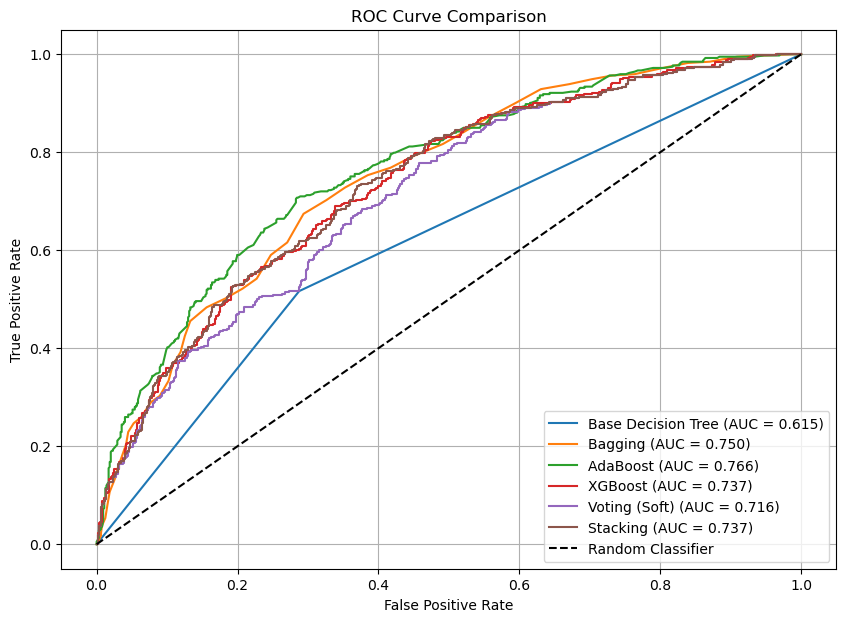

,Model,AUC Score
2,AdaBoost,0.7665
1,Bagging,0.7500
3,XGBoost,0.7375
5,Stacking,0.7374
4,Voting (Soft),0.7156
0,Base Decision Tree,0.6145



BEST MODEL BASED ON AUC
Model: AdaBoost
AUC Score: 0.7665


In [53]:
from sklearn.metrics import roc_curve, roc_auc_score

roc_results = []

plt.figure(figsize=(10, 7))

for name, model in classification_models.items():

    # Skip Voting Hard because it does not provide probabilities
    if name == "Voting (Hard)":
        print("Skipping Voting (Hard): ROC curve requires probability scores.")
        continue

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train_c, y_train_c)

    # Get probability scores
    if hasattr(pipeline, "predict_proba"):
        y_score = pipeline.predict_proba(X_test_c)[:, 1]

    elif hasattr(pipeline, "decision_function"):
        y_score = pipeline.decision_function(X_test_c)

    else:
        print(f"Skipping {name}: no probability or decision scores.")
        continue

    # Calculate ROC and AUC
    auc_score = roc_auc_score(y_test_c, y_score)
    fpr, tpr, thresholds = roc_curve(y_test_c, y_score)

    roc_results.append({
        "Model": name,
        "AUC Score": auc_score
    })

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random classifier line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Display results
roc_df = pd.DataFrame(roc_results)

roc_df = roc_df.sort_values(
    by="AUC Score",
    ascending=False
)

display(roc_df.round(4))

# Best model based on AUC
if not roc_df.empty:
    best_model = roc_df.iloc[0]

    print("\nBEST MODEL BASED ON AUC")
    print("Model:", best_model["Model"])
    print("AUC Score:", round(best_model["AUC Score"], 4))

In [55]:
joblib.dump(best_classification, model_path / "best_classification_pipeline.pkl")
joblib.dump(best_regression, model_path / "best_regression_pipeline.pkl")

['C:\\Users\\mantr\\Downloads\\Smart outcome Predictor\\Model\\best_regression_pipeline.pkl']